(d) Simulate the two-population model with μ = 0.2, σ = 0.5, I0 = 5, ws = wc = (1 + λ)/2 for λ = 0 and λ = 0.2, starting at r1 = r2 = I0. Use Euler–Maruyama with dt = 0.002 and 104 trials for each θ ∈ {0.5, 1, . . . , 4}. Plot accuracy and mean decision time against θ together with the predictions from (b) and (c). At λ = 0.2 and θ = 4, compare the accuracy and decision time with those of the perfect integrator at the threshold giving the same accuracy.

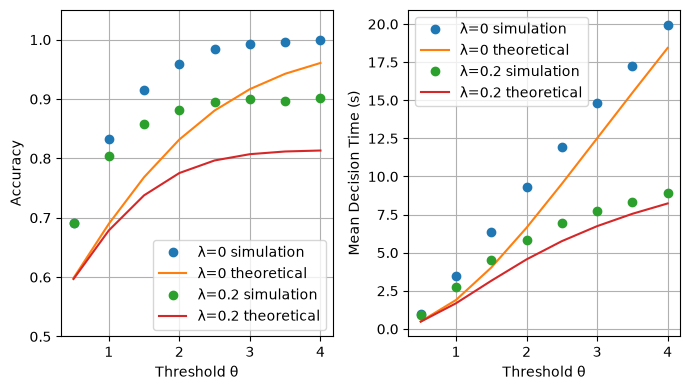

λ = 0.2, θ = 4
Accuracy = 0.9013
Mean Decision Time = 8.9498 s
Perfect integrator is at equal accuracy
Matching threshold θ = 2.7647
Mean decisision time = 11.0947 s


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_bvp

# Parameters
mu = 0.2
sigma = 0.5
I0 = 5
dt = 0.002
n_trials = 10**4
theta_values = np.arange(0.5, 4.1, 0.5)
lambda_values = [0, 0.2]

def simulate(theta, lambda_val):
    d = np.zeros(n_trials)
    times = np.zeros(n_trials)
    active = np.ones(n_trials, dtype = bool)
    correct = np.zeros(n_trials, dtype = bool)

    while active.any():
        i = np.flatnonzero(active)
        d[i] += ((lambda_val * d[i] + mu) * dt) + np.sqrt(dt) * sigma * np.random.randn(len(i))
        times[i] += dt
        upper = d[i] >= theta
        lower = d[i] <= -theta
        finished = upper | lower

        correct[i[upper]] = True
        active[i[finished]] = False

    return correct.mean(), times.mean()

def theoretical_accuracy(theta, lambda_val):
    y = np.linspace(-theta, theta, 2000)
    g = np.exp(-(lambda_val * y ** 2 + 2 * mu * y) / (2 * sigma ** 2) )
    return np.trapezoid(g[y <= 0], y[y <= 0]) / np.trapezoid(g, y)

def theoretical_time(theta, lambda_val):
    def ode(x, u):
        return np.vstack((u[1], (-1 - (lambda_val * x + mu) * u[1]) / sigma ** 2))

    def bc(ua, ub):
        return np.array([ua[0], ub[0]])
        
    x = np.linspace(-theta, theta, 200)
    guess = np.vstack((np.zeros_like(x), np.zeros_like(x)))
    sol = solve_bvp(ode, bc, x, guess)
    return sol.sol(0)[0]

def perfect_int_time(theta):
    return theta / mu * np.tanh(mu * theta / (2 * sigma ** 2))

# Simulations
results = {}
for lambda_val in lambda_values:
    acc_sim, time_sim = [], []
    for theta in theta_values:
        a, t = simulate(theta, lambda_val)
        acc_sim.append(a)
        time_sim.append(t)

    results[lambda_val] = (np.array(acc_sim), np.array(time_sim))

# Plot
fig, axes = plt.subplots(1, 2, figsize = (7, 4))
for lambda_val in lambda_values:
    acc, times = results[lambda_val]
    acc_theory = [theoretical_accuracy(theta, lambda_val) for theta in theta_values]
    time_theory = [theoretical_time(theta, lambda_val) for theta in theta_values]

    axes[0].plot(theta_values, acc, 'o', label = f'λ={lambda_val} simulation')
    axes[0].plot(theta_values, acc_theory, '-', label = f'λ={lambda_val} theoretical')
    axes[1].plot(theta_values, times, 'o', label = f'λ={lambda_val} simulation')
    axes[1].plot(theta_values, time_theory, '-', label = f'λ={lambda_val} theoretical')
    
axes[0].set(xlabel = "Threshold θ", ylabel = "Accuracy", ylim = (0.5, 1.05))
axes[1].set(xlabel = "Threshold θ", ylabel = "Mean Decision Time (s)")

for ax in axes:
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.show()

# Comparison with perfect integrator
acc_2, time_2 = results[0.2]
accuracy = acc_2[-1]

theta_match = (sigma ** 2 / mu) * np.log(accuracy / (1 - accuracy))
time_match = perfect_int_time(theta_match)

print(f"λ = 0.2, θ = 4")
print(f"Accuracy = {accuracy:.4f}")
print(f"Mean Decision Time = {time_2[-1]:.4f} s")
print(f"Perfect integrator is at equal accuracy")
print(f"Matching threshold θ = {theta_match:.4f}")
print(f"Mean decisision time = {time_match:.4f} s")